In [1]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   --------- ------------------------------ 2.6/11.4 MB 18.9 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.4 MB 27.4 MB/s eta 0:00:01
   ---------------------------------------- 11.4/11.4 MB 22.2 MB/s  0:00:00

   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------------------------------------- 0/4 [patsy]
   ---------- ----------------------------- 1/4 [interface-meta]
   ---------- ----------------------------- 1/4 [interface-meta]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formulaic]
   -------------------- ------------------- 2/4 [formul

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)

Task 1, regplot of Instagram likes vs comments (12 posts)

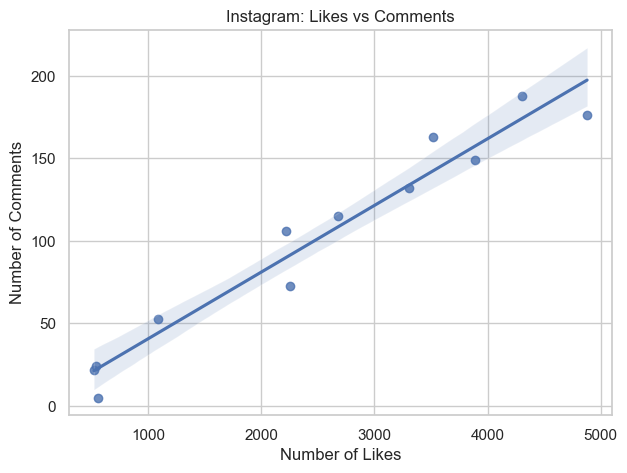

In [3]:
likes = rng.integers(100, 5000, 12)
comments = (likes * 0.04 + rng.normal(0, 20, 12)).clip(1).round(0)
insta = pd.DataFrame({'likes': likes, 'comments': comments})

plt.figure(figsize=(7, 5))
sns.regplot(data=insta, x='likes', y='comments')
plt.xlabel('Number of Likes')
plt.ylabel('Number of Comments')
plt.title('Instagram: Likes vs Comments')
plt.show()

Task 2, lmplot of Zomato price vs delivery time (20 rows)

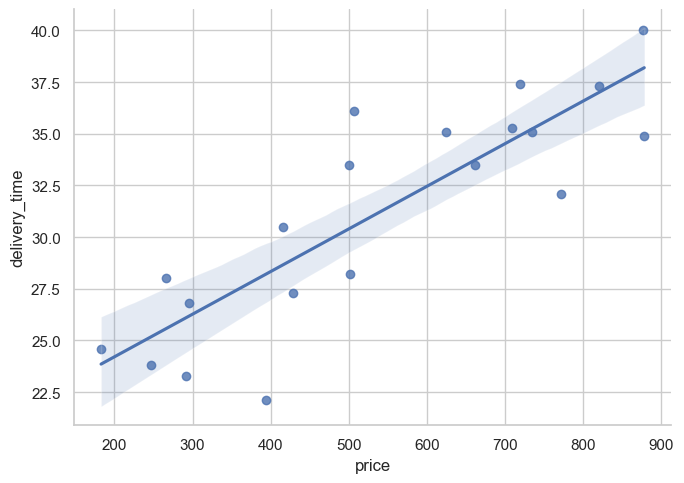

In [4]:
price = rng.uniform(150, 900, 20).round(0)
delivery_time = (20 + price * 0.02 + rng.normal(0, 4, 20)).round(1)
zomato = pd.DataFrame({'price': price, 'delivery_time': delivery_time})

sns.lmplot(data=zomato, x='price', y='delivery_time', height=5, aspect=1.4)
plt.show()

Task 3, linear vs lowess for Spotify playlists

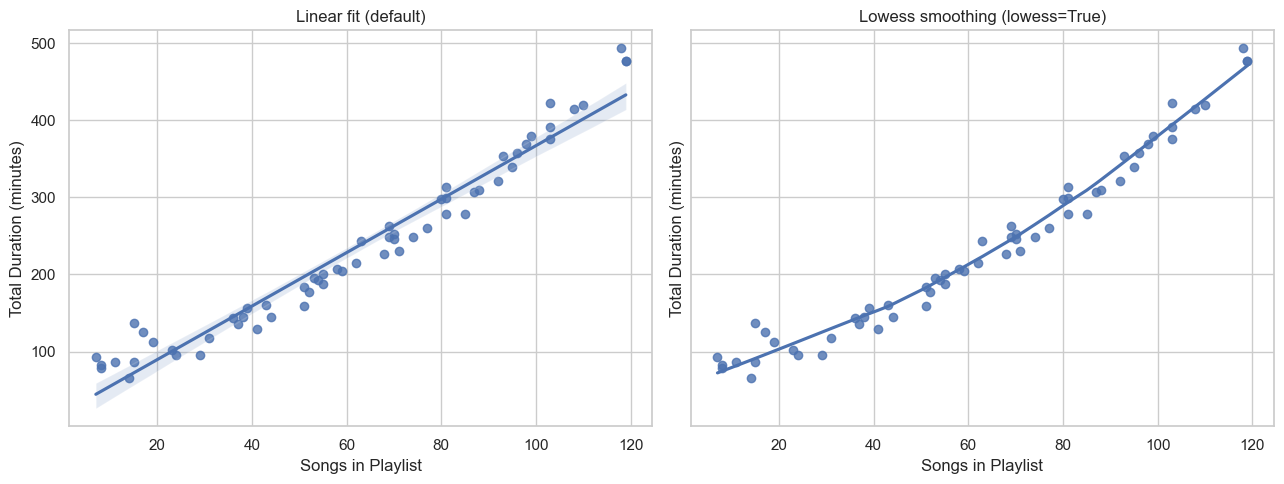

In [5]:
songs = rng.integers(5, 120, 60)
duration = (songs * 3.5 + 0.02 * (songs - 60) ** 2 + rng.normal(0, 15, 60)).clip(10).round(0)
spotify = pd.DataFrame({'num_songs': songs, 'duration_min': duration})

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
sns.regplot(data=spotify, x='num_songs', y='duration_min', ax=axes[0])
axes[0].set_title('Linear fit (default)')
sns.regplot(data=spotify, x='num_songs', y='duration_min', lowess=True, ax=axes[1])
axes[1].set_title('Lowess smoothing (lowess=True)')
for ax in axes:
    ax.set_xlabel('Songs in Playlist')
    ax.set_ylabel('Total Duration (minutes)')
plt.tight_layout()
plt.show()

Task 4, faceted regression by preparation method

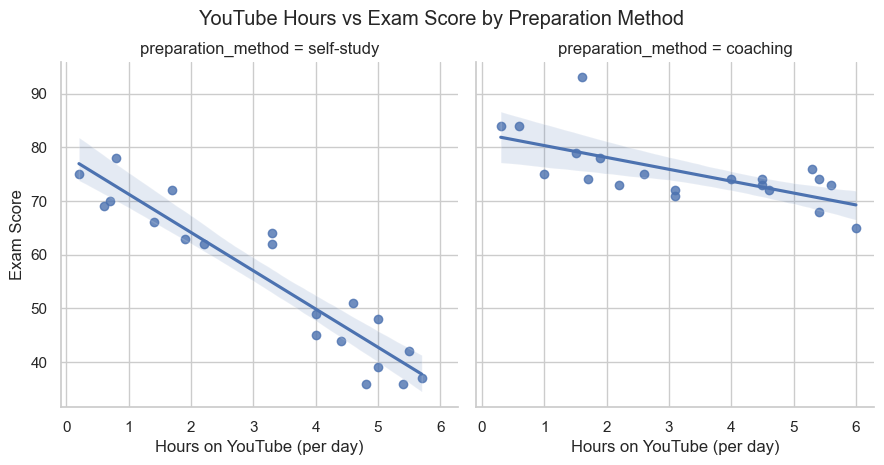

In [6]:
p = 40
prep = np.array(['self-study'] * 20 + ['coaching'] * 20)
hours = rng.uniform(0, 6, p).round(1)
base = np.where(prep == 'coaching', 85, 75)
scores = (base - hours * np.where(prep == 'coaching', 3, 6) + rng.normal(0, 5, p)).clip(0, 100).round(0)
exam = pd.DataFrame({'youtube_hours': hours, 'exam_score': scores, 'preparation_method': prep})

g = sns.lmplot(data=exam, x='youtube_hours', y='exam_score', col='preparation_method', height=4.5)
g.set_axis_labels('Hours on YouTube (per day)', 'Exam Score')
g.figure.suptitle('YouTube Hours vs Exam Score by Preparation Method', y=1.03)
plt.show()